# Lab 7 · Example A — IMDB Sentiment with a Bidirectional LSTM
### Deep Learning Laboratory (23DS5PCDLG) · Student Fill-in Notebook

**Goal.** Read a movie review and classify it as **positive** or **negative** (binary). You will
turn text into integer indices, pad them, learn **word embeddings**, summarise each review with a
**Bidirectional LSTM**, and decide with a **sigmoid** output.

---
Replace every `None  # TODO (Qn)` with the correct value/code. Run top to bottom.
*(Needs internet once to download the IMDB dataset — works on Colab.)*


## Step 0 — Imports *(given)*

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout, Input
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## Task 1 — Load and pad the data

IMDB reviews come **already encoded as integer indices**. Keep the top `num_words` words and pad
every review to `maxlen` tokens.

*Hints:* keep the 10000 most frequent words; pad to length 200.


In [2]:
# Q1a) hyperparameters
num_words = 10000     # TODO (Q1a): keep the 10000 most frequent words
maxlen    = 200     # TODO (Q1a): fix every review to 200 tokens

(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=num_words)

# Q1b) pad both sets to a fixed length
X_train = pad_sequences(X_train, maxlen=maxlen)   # TODO (Q1b): maxlen
X_test  = pad_sequences(X_test,  maxlen=maxlen)   # TODO (Q1b): maxlen

# Q1c) hold out 20% of training data for validation
X_train, X_val, y_train, y_val = train_test_split(
        X_train, y_train, test_size=0.2, random_state=42)   # TODO (Q1c): 0.2

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
X_train: (20000, 200)  X_val: (5000, 200)  X_test: (25000, 200)


#### Quick check *(given)*

In [ ]:
assert X_train.shape[1] == 200, "reviews should be padded to length 200"
assert set(np.unique(y_train)) <= {0, 1}, "labels should be binary (0/1)"
print("Task 1 looks correct ✔   expected ~ (20000, 200) / (5000, 200) / (25000, 200)")

## Task 2 — Build the model

Stack: **Embedding** (vocabulary `num_words`, 128-dim vectors) → **Bidirectional LSTM(64)**
returning a single summary vector → **Dropout(0.5)** → **Dense(1, sigmoid)**.

*Hints:* `Embedding(input_dim=num_words, output_dim=128)`; a bidirectional LSTM that returns one
vector uses `return_sequences=False`; one output neuron with a sigmoid gives a probability.


In [3]:
model = Sequential()
model.add(Input(shape=(maxlen,)))

# Q2a) Embedding: vocabulary size -> 128-dim word vectors
model.add(Embedding(input_dim=num_words, output_dim=128))   # TODO (Q2a): num_words, 128

# Q2b) Bidirectional LSTM with 64 units, returning ONE summary vector
model.add(Bidirectional(LSTM(64, return_sequences=False)))   # TODO (Q2b): 64, False

# Q2c) Dropout to reduce overfitting
model.add(Dropout(0.5))   # TODO (Q2c): 0.5

# Q2d) Output: one neuron, sigmoid (positive/negative probability)
model.add(Dense(1, activation='sigmoid'))   # TODO (Q2d): 1, 'sigmoid'

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,378,945 (5.26 MB)

 Trainable params: 1,378,945 (5.26 MB)

 Non-trainable params: 0 (0.00 B)

**Reflection Q2e.** The Embedding layer shows **1,280,000** parameters. Show why with
`num_words × embed_dim`. Why does this one layer hold most of the model's parameters?

> **Your answer (Q2e):** 1,280,000 = ____ × ____ ; it dominates because ____.


## Task 3 — Compile and train

Use the **adam** optimiser, **binary crossentropy** loss (one sigmoid output), track accuracy.
Train 5 epochs, batch size 64, validating on `(X_val, y_val)`.


In [4]:
# Q3a) compile for binary classification
model.compile(optimizer='adam',
              loss='binary_crossentropy',              # TODO (Q3a): 'binary_crossentropy'
              metrics=['accuracy'])

# Q3b) train
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=5,          # TODO (Q3b): 5
                    batch_size=64)      # TODO (Q3b): 64

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 96s 301ms/step - accuracy: 0.7532 - loss: 0.4968 - val_accuracy: 0.8292 - val_loss: 0.3976
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 138s 290ms/step - accuracy: 0.8932 - loss: 0.2763 - val_accuracy: 0.8758 - val_loss: 0.2990
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 86s 276ms/step - accuracy: 0.9227 - loss: 0.2044 - val_accuracy: 0.8652 - val_loss: 0.3380
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 91s 291ms/step - accuracy: 0.9415 - loss: 0.1622 - val_accuracy: 0.8668 - val_loss: 0.3517
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 137s 274ms/step - accuracy: 0.9598 - loss: 0.1127 - val_accuracy: 0.8664 - val_loss: 0.3824


## Task 4 — Evaluate and plot *(fill the blanks)*

782/782 ━━━━━━━━━━━━━━━━━━━━ 31s 40ms/step - accuracy: 0.8605 - loss: 0.4002
Test accuracy: 86.05%


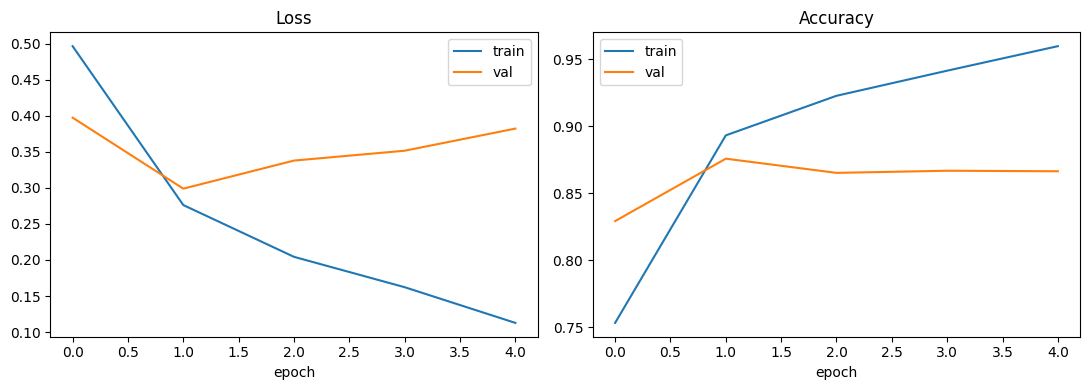

In [5]:
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Test accuracy: {accuracy*100:.2f}%")   # expect ~ 86-88%

plt.figure(figsize=(11,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')      # TODO (Q4a): 'val_loss'
plt.title('Loss'); plt.xlabel('epoch'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')      # TODO (Q4b): 'val_accuracy'
plt.title('Accuracy'); plt.xlabel('epoch'); plt.legend()
plt.tight_layout(); plt.show()

## Task 5 — Predict on your own text *(fill the blanks)*

IMDB reserves indices 0–2 (pad / start / unknown), so real words are **offset by 3**.


In [6]:
word_index = imdb.get_word_index()

def predict_sentiment(review):
    enc = [word_index.get(w, 0) + 3 for w in review.lower().split()]
    padded = pad_sequences([enc], maxlen=maxlen)
    p = model.predict(padded, verbose=0)[0][0]
    # Q5) threshold the sigmoid at 0.5
    return "Positive" if p >= 0.5 else "Negative"   # TODO (Q5): 0.5

for r in ["this film was absolutely wonderful and moving",
          "a boring dull waste of time"]:
    print(f"{predict_sentiment(r):8s} <- {r}")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Positive <- this film was absolutely wonderful and moving
Negative <- a boring dull waste of time


## Task 6 — Short questions *(write answers here)*

1. Why do we **pad** every review to the same length?
2. What does the **Embedding** layer do that one-hot encoding of words would not?
3. Why `return_sequences=False` here (unlike the music lab)?
4. Why `sigmoid` + `binary_crossentropy` instead of `softmax` + `categorical_crossentropy`?
5. In your accuracy plot, does validation loss start rising? What does that indicate, and what
   does `Dropout(0.5)` do about it?

> **Your answers:** 1. … 2. … 3. … 4. … 5. …


Task 6 — Short Questions
1. We pad every review to the same length so that all reviews have an equal number of tokens and can be given as input to the model.

2. The Embedding layer converts words into dense numerical vectors that can capture meaning and relationships between words, unlike one-hot encoding.

3. We use return_sequences=False because we need one final output vector for classifying the entire review, not an output for every word.

4. We use sigmoid and binary crossentropy because IMDB has only two classes (positive and negative). Softmax is mainly used for multi-class classification.

5. If validation loss starts increasing, it indicates overfitting, which means the model is learning the training data too much. Dropout(0.5) randomly turns off 50% of neurons during training to reduce overfitting.